In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import cifar10
import matplotlib.pyplot as plt
import numpy as np

In [2]:
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [3]:
train_images.shape

(50000, 32, 32, 3)

In [4]:
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

In [5]:
train_labels = to_categorical(train_labels, 10)
test_labels = to_categorical(test_labels, 10)

In [6]:
from tensorflow.keras.applications import MobileNetV2

In [7]:
base_model = MobileNetV2(input_shape=(32, 32, 3),
                         include_top=False,
                         weights='imagenet')

/tmp/ipykernel_2220/3075239769.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(32, 32, 3),


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [8]:
base_model.trainable = False

In [9]:
tl_model = Sequential([
    base_model,
    GlobalAveragePooling2D(), #parametrleri azaltdim
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

In [10]:
tl_model.compile(optimizer=Adam(learning_rate=0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

In [11]:
tl_h= tl_model.fit(
    train_images,
    train_labels,
    epochs=10,
    batch_size=64,
    validation_data=(test_images, test_labels)
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 59s 67ms/step - accuracy: 0.2842 - loss: 1.9844 - val_accuracy: 0.3183 - val_loss: 1.8866
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 80s 66ms/step - accuracy: 0.3198 - loss: 1.8767 - val_accuracy: 0.3296 - val_loss: 1.8509
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 84s 69ms/step - accuracy: 0.3297 - loss: 1.8413 - val_accuracy: 0.3328 - val_loss: 1.8312
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 56s 71ms/step - accuracy: 0.3391 - loss: 1.8219 - val_accuracy: 0.3436 - val_loss: 1.8207
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 80s 69ms/step - accuracy: 0.3436 - loss: 1.8081 - val_accuracy: 0.3455 - val_loss: 1.8108
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 52s 66ms/step - accuracy: 0.3487 - loss: 1.7939 - val_accuracy: 0.3457 - val_loss: 1.8060
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 50s 64ms/step - accuracy: 0.3515 - loss: 1.7868 - val_accuracy: 0.3518 - val_loss: 1.7998
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 85s 69ms/step - accuracy: 0.3544 - loss: 1.7765 - 

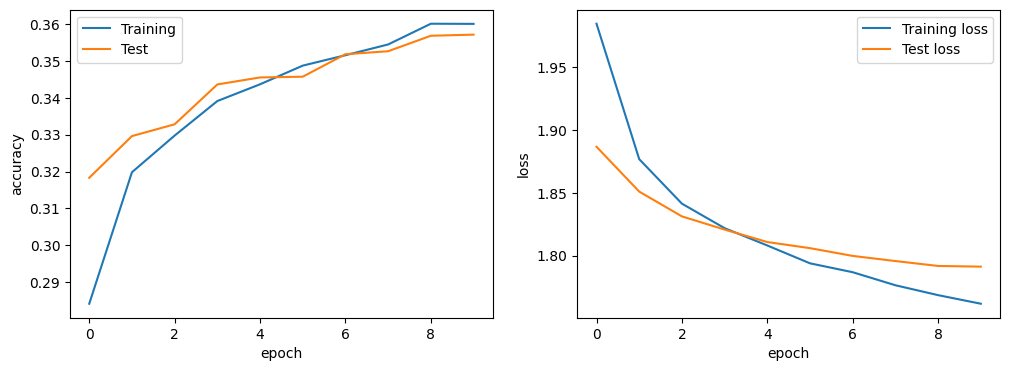

In [12]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(tl_h.history['accuracy'], label='Training')
plt.plot(tl_h.history['val_accuracy'], label='Test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(tl_h.history['loss'], label='Training loss')
plt.plot(tl_h.history['val_loss'], label='Test loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [13]:
base_model.trainable = True

In [14]:
len(base_model.layers)

154

In [15]:
fine_tune_at = 154

In [16]:
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

In [17]:
tl_model.compile(optimizer=Adam(learning_rate=0.0001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

In [18]:
hf= tl_model.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_data=(test_images, test_labels)
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 80s 47ms/step - accuracy: 0.3661 - loss: 1.7458 - val_accuracy: 0.3566 - val_loss: 1.7880
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 77s 49ms/step - accuracy: 0.3693 - loss: 1.7407 - val_accuracy: 0.3588 - val_loss: 1.7875
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 46ms/step - accuracy: 0.3722 - loss: 1.7404 - val_accuracy: 0.3564 - val_loss: 1.7873
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.3683 - loss: 1.7380 - val_accuracy: 0.3590 - val_loss: 1.7872
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.3704 - loss: 1.7364 - val_accuracy: 0.3597 - val_loss: 1.7868
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 80s 41ms/step - accuracy: 0.3705 - loss: 1.7351 - val_accuracy: 0.3615 - val_loss: 1.7864
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 63s 41ms/step - accuracy: 0.3719 - loss: 1.7348 - val_accuracy: 0.3591 - val_loss: 1.7863
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 63s 41ms/step - accuracy: 0.3730 -

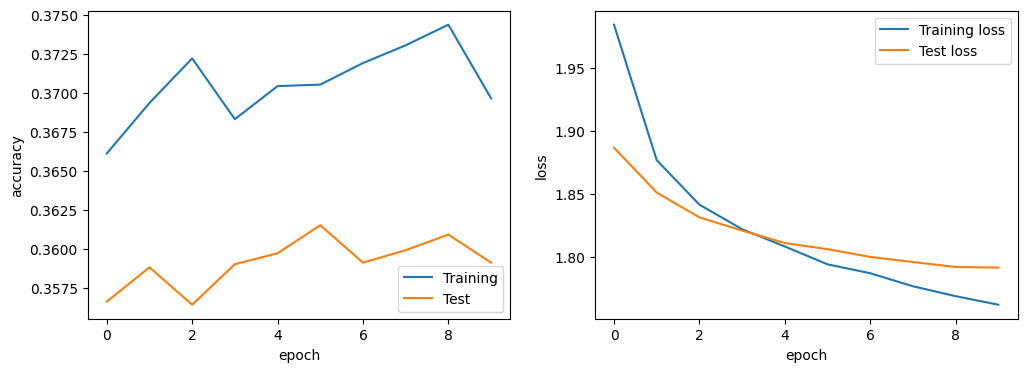

In [20]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hf.history['accuracy'], label='Training')
plt.plot(hf.history['val_accuracy'], label='Test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(tl_h.history['loss'], label='Training loss')
plt.plot(tl_h.history['val_loss'], label='Test loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [19]:
import numpy as np

In [21]:
classes = ['təyyarə', 'maşın', 'quş', 'pişik', 'maral', 'it', 'qurbağa', 'at', 'gəmi', 'yük maşını']

In [22]:
index = np.random.randint(0, len(test_images))
test_img = test_images[index]

In [27]:
prediction = tl_model.predict(np.expand_dims(test_img, axis=0))
predicted_class = classes[np.argmax(prediction)]
true_class = classes[np.argmax(test_labels[index])]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


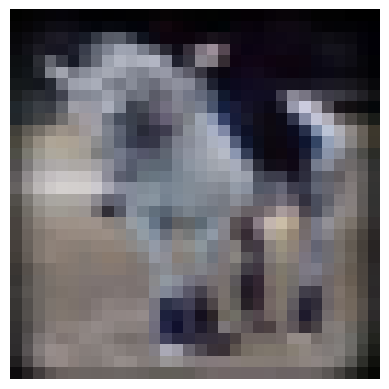

failed


In [28]:
plt.imshow(test_img)
plt.axis('off')
plt.show()
if predicted_class == true_class:
    print("found")
else:
    print("failed")